# بخش 4: GRU

LSTM را با GRU جایگزین کنید.

In [27]:
%load_ext autoreload
%autoreload 2

import sys
from pathlib import Path
sys.path.append(str(Path.cwd().parent / 'src'))

import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.optim as optim
import time
import matplotlib.pyplot as plt
from torch.utils.data import DataLoader

from data_utils import get_dataloaders
from plotting import save_figure, save_table, plot_models_comparison_bar, plot_gru_gates


The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [2]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
torch.manual_seed(42)
np.random.seed(42)
data_path = None
batch_size = 64
hidden_size = 64
seq_length = 20
epochs = 50
learning_rate = 0.01


4-1 آزمایش 1: مقایسه سه معماری

سه معماری RNN، LSTM و GRU را با تنظیمات یکسان (اندازه نهان 64، طول پنجره 20) مقایسه کنید. معیارهای زیر را گزارش دهید:

•	میانگین مربعات خطا (MSE)

•	میانگین قدر مطلق خطا (MAE)

•	زمان آموزش برای 50 دوره (epoch)

•	تعداد پارامترهای قابل آموزش

یک جدول مقایسه تهیه کنید و مزایا/معایب هر مدل را بحث کنید.


In [4]:
# CELL 2: Define RNN, LSTM, GRU Models

class SimpleRNN(nn.Module):
    def __init__(self, input_size=5, hidden_size=64, num_layers=1, output_size=1):
        super(SimpleRNN, self).__init__()
        self.hidden_size = hidden_size
        self.rnn = nn.RNN(input_size, hidden_size, num_layers, batch_first=True, nonlinearity='tanh')
        self.fc = nn.Linear(hidden_size, output_size)
    
    def forward(self, x):
        h0 = torch.zeros(1, x.size(0), self.hidden_size).to(x.device)
        out, _ = self.rnn(x, h0)
        out = out[:, -1, :]
        return self.fc(out).squeeze(-1)

class SimpleLSTM(nn.Module):
    def __init__(self, input_size=5, hidden_size=64, num_layers=1, output_size=1):
        super(SimpleLSTM, self).__init__()
        self.hidden_size = hidden_size
        self.lstm = nn.LSTM(input_size, hidden_size, num_layers, batch_first=True)
        self.fc = nn.Linear(hidden_size, output_size)
    
    def forward(self, x):
        h0 = torch.zeros(1, x.size(0), self.hidden_size).to(x.device)
        c0 = torch.zeros(1, x.size(0), self.hidden_size).to(x.device)
        out, _ = self.lstm(x, (h0, c0))
        out = out[:, -1, :]
        return self.fc(out).squeeze(-1)

class SimpleGRU(nn.Module):
    def __init__(self, input_size=5, hidden_size=64, num_layers=1, output_size=1):
        super(SimpleGRU, self).__init__()
        self.hidden_size = hidden_size
        self.gru = nn.GRU(input_size, hidden_size, num_layers, batch_first=True)
        self.fc = nn.Linear(hidden_size, output_size)
    
    def forward(self, x):
        h0 = torch.zeros(1, x.size(0), self.hidden_size).to(x.device)
        out, _ = self.gru(x, h0)
        out = out[:, -1, :]
        return self.fc(out).squeeze(-1)

In [5]:
# CELL 3: Training Function with Metrics

def train_model_full(model, train_loader, test_loader, epochs=50, lr=0.01, verbose=True):
    model = model.to(device)
    criterion = nn.MSELoss()
    optimizer = optim.Adam(model.parameters(), lr=lr)
    
    train_losses = []
    test_losses = []
    start_time = time.time()
    
    for epoch in range(epochs):
        model.train()
        epoch_loss = 0.0
        for X_batch, y_batch in train_loader:
            X_batch, y_batch = X_batch.to(device), y_batch.to(device)
            optimizer.zero_grad()
            outputs = model(X_batch)
            loss = criterion(outputs, y_batch)
            loss.backward()
            optimizer.step()
            epoch_loss += loss.item()
        avg_train_loss = epoch_loss / len(train_loader)
        train_losses.append(avg_train_loss)
        
        model.eval()
        test_loss = 0.0
        with torch.no_grad():
            for X_batch, y_batch in test_loader:
                X_batch, y_batch = X_batch.to(device), y_batch.to(device)
                outputs = model(X_batch)
                loss = criterion(outputs, y_batch)
                test_loss += loss.item()
        avg_test_loss = test_loss / len(test_loader)
        test_losses.append(avg_test_loss)
        
        if verbose and (epoch+1) % 10 == 0:
            print(f"{model.__class__.__name__:6s} Epoch {epoch+1:2d}/{epochs} | Train Loss: {avg_train_loss:.6f} | Test Loss: {avg_test_loss:.6f}")
    
    training_time = time.time() - start_time
    final_test_loss = test_losses[-1]
    
    # Compute MAE on test set
    model.eval()
    all_preds = []
    all_targets = []
    with torch.no_grad():
        for X_batch, y_batch in test_loader:
            X_batch, y_batch = X_batch.to(device), y_batch.to(device)
            preds = model(X_batch)
            all_preds.append(preds.cpu().numpy())
            all_targets.append(y_batch.cpu().numpy())
    all_preds = np.concatenate(all_preds)
    all_targets = np.concatenate(all_targets)
    mae = np.mean(np.abs(all_preds - all_targets))
    
    return final_test_loss, mae, training_time

In [6]:
train_loader, test_loader, _ = get_dataloaders(
    seq_length=seq_length, batch_size=batch_size, data_path=data_path
)


In [7]:
models = {
    'RNN': SimpleRNN(input_size=5, hidden_size=hidden_size, output_size=1),
    'LSTM': SimpleLSTM(input_size=5, hidden_size=hidden_size, output_size=1),
    'GRU': SimpleGRU(input_size=5, hidden_size=hidden_size, output_size=1)
}


In [8]:

results = []

for name, model in models.items():
    print(f"\n--- Training {name} ---")
    num_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
    mse, mae, train_time = train_model_full(model, train_loader, test_loader, epochs=epochs, lr=learning_rate, verbose=True)
    results.append({
        'Model': name,
        'MSE': mse,
        'MAE': mae,
        'Training Time (s)': train_time,
        'Parameters': num_params
    })
    print(f"{name} -> MSE: {mse:.6f}, MAE: {mae:.6f}, Time: {train_time:.2f}s, Params: {num_params:,}")



--- Training RNN ---
SimpleRNN Epoch 10/50 | Train Loss: 0.421075 | Test Loss: 0.527111
SimpleRNN Epoch 20/50 | Train Loss: 0.430753 | Test Loss: 0.405392
SimpleRNN Epoch 30/50 | Train Loss: 0.424417 | Test Loss: 0.402320
SimpleRNN Epoch 40/50 | Train Loss: 0.419202 | Test Loss: 0.402642
SimpleRNN Epoch 50/50 | Train Loss: 0.419752 | Test Loss: 0.405837
RNN -> MSE: 0.405837, MAE: 0.507697, Time: 69.48s, Params: 4,609

--- Training LSTM ---
SimpleLSTM Epoch 10/50 | Train Loss: 0.398006 | Test Loss: 0.393894
SimpleLSTM Epoch 20/50 | Train Loss: 0.396946 | Test Loss: 0.393330
SimpleLSTM Epoch 30/50 | Train Loss: 0.395898 | Test Loss: 0.393559
SimpleLSTM Epoch 40/50 | Train Loss: 0.396047 | Test Loss: 0.395533
SimpleLSTM Epoch 50/50 | Train Loss: 0.395292 | Test Loss: 0.395293
LSTM -> MSE: 0.395293, MAE: 0.501952, Time: 73.10s, Params: 18,241

--- Training GRU ---
SimpleGRU Epoch 10/50 | Train Loss: 0.409388 | Test Loss: 0.406536
SimpleGRU Epoch 20/50 | Train Loss: 0.408090 | Test Loss: 0

In [9]:

# Create comparison table
df_comparison = pd.DataFrame(results)
print("\n" + "="*70)
print("COMPARISON TABLE")
print("="*70)
print(df_comparison.to_string(index=False))
save_table(df_comparison, 'rnn_lstm_gru_comparison')



COMPARISON TABLE
Model      MSE      MAE  Training Time (s)  Parameters
  RNN 0.405837 0.507697          69.482394        4609
 LSTM 0.395293 0.501952          73.095319       18241
  GRU 0.422971 0.519295          70.835742       13697


,Model,MSE,MAE,Training Time (s),Parameters
0,RNN,0.405837,0.507697,69.482394,4609
1,LSTM,0.395293,0.501952,73.095319,18241
2,GRU,0.422971,0.519295,70.835742,13697


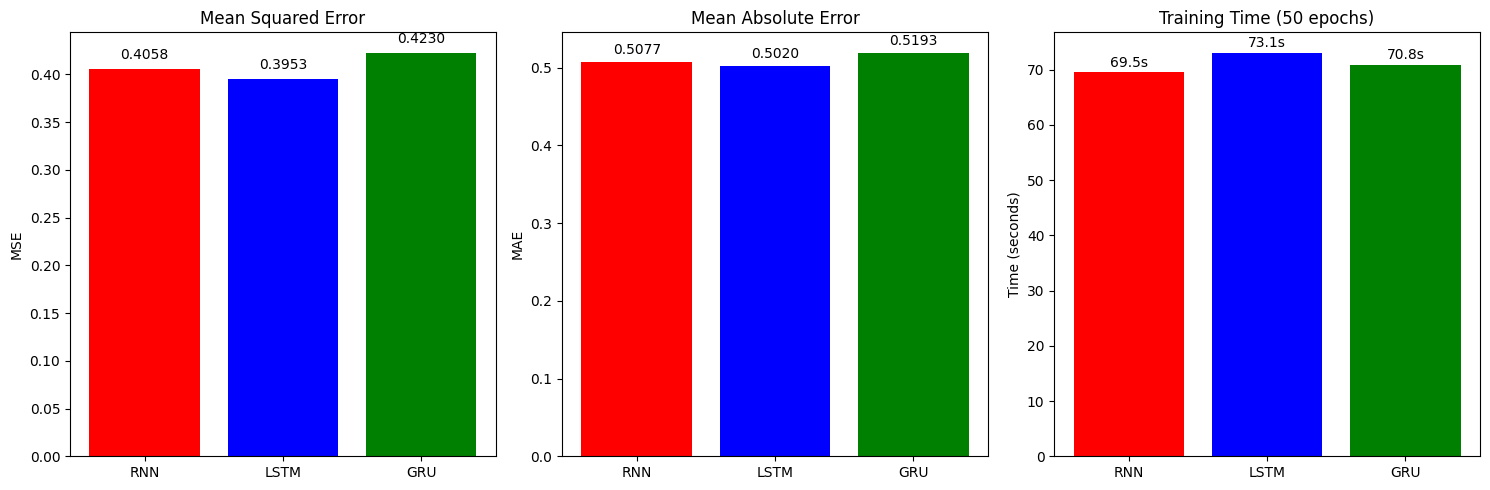

In [10]:

# Bar chart comparison
plot_models_comparison_bar(
    df_comparison['Model'].tolist(),
    df_comparison['MSE'].tolist(),
    df_comparison['MAE'].tolist(),
    df_comparison['Training Time (s)'].tolist(),
    df_comparison['Parameters'].tolist(),
    save_name="models_comparison"
)


4-2 آزمایش 2: تحلیل دروازه‌ های  GRU

دروازه بازنشانی (reset gate) و دروازه به‌روزرسانی (update gate) را برای چند گام زمانی خروجی گرفته و نمودار تغییرات آنها را رسم کنید.

آیا می توانید رفتاری معنادار از نظر یادگیری وابستگی کوتاه مدت/بلندمدت مشاهده کنید؟


In [11]:
# CELL 5: Experiment 4-2 - GRU Gate Analysis

print("\n" + "="*70)
print("EXPERIMENT 4-2: GRU Gate Analysis (Reset and Update Gates)")
print("="*70)

# Custom GRU that returns gates at each time step
class GRUWithGates(nn.Module):
    def __init__(self, input_size=5, hidden_size=64, output_size=1):
        super(GRUWithGates, self).__init__()
        self.hidden_size = hidden_size
        # GRU cell (to manually loop and record gates)
        self.gru_cell = nn.GRUCell(input_size, hidden_size)
        self.fc = nn.Linear(hidden_size, output_size)
    
    def forward(self, x, return_gates=False):
        # x: (batch, seq_len, input_size)
        batch_size, seq_len, _ = x.shape
        h = torch.zeros(batch_size, self.hidden_size).to(x.device)
        
        if return_gates:
            update_gates = []
            reset_gates = []
        
        for t in range(seq_len):
            x_t = x[:, t, :]
            # GRUCell internal gates are not directly accessible.
            # We need to implement GRU cell manually to get gates.
            # For simplicity, we'll use a custom GRUCell that exposes gates.
            # We'll define a custom cell below.
            # This is placeholder; actual implementation follows.
            h = self.gru_cell(x_t, h)
            # To get gates, we need custom cell. Let's implement a GRUCellWithGates.
        
        out = self.fc(h).squeeze(-1)
        if return_gates:
            return out, update_gates, reset_gates
        return out



EXPERIMENT 4-2: GRU Gate Analysis (Reset and Update Gates)


In [20]:

# Proper custom GRU cell with gate outputs
class GRUCellWithGates(nn.Module):
    def __init__(self, input_size, hidden_size):
        super(GRUCellWithGates, self).__init__()
        self.hidden_size = hidden_size
        self.W_ir = nn.Linear(input_size, hidden_size, bias=True)
        self.W_iz = nn.Linear(input_size, hidden_size, bias=True)
        self.W_in = nn.Linear(input_size, hidden_size, bias=True)
        self.W_hr = nn.Linear(hidden_size, hidden_size, bias=True)
        self.W_hz = nn.Linear(hidden_size, hidden_size, bias=True)
        self.W_hn = nn.Linear(hidden_size, hidden_size, bias=True)
    
    def forward(self, x, h):
        # x: (batch, input_size), h: (batch, hidden_size)
        r = torch.sigmoid(self.W_ir(x) + self.W_hr(h))
        z = torch.sigmoid(self.W_iz(x) + self.W_hz(h))
        n = torch.tanh(self.W_in(x) + r * self.W_hn(h))
        h_new = (1 - z) * n + z * h
        return h_new, r, z
    
class GRUModelWithGates(nn.Module):
    def __init__(self, input_size=5, hidden_size=64, output_size=1):
        super(GRUModelWithGates, self).__init__()
        self.hidden_size = hidden_size
        self.cell = GRUCellWithGates(input_size, hidden_size)
        self.fc = nn.Linear(hidden_size, output_size)
    
    def forward(self, x, return_gates=False):
        batch_size, seq_len, _ = x.shape
        h = torch.zeros(batch_size, self.hidden_size).to(x.device)
        if return_gates:
            reset_gates = []
            update_gates = []
        for t in range(seq_len):
            x_t = x[:, t, :]
            h, r, z = self.cell(x_t, h)
            if return_gates:
                # Take mean over hidden dimension for the first sample in batch
                reset_gates.append(r[0].mean().item())
                update_gates.append(z[0].mean().item())
        out = self.fc(h).squeeze(-1)
        if return_gates:
            return out, update_gates, reset_gates
        return out

In [21]:

# Train the GRU model with gates for analysis
print("\nTraining GRU with gate recording capability...")
model_gates = GRUModelWithGates(input_size=5, hidden_size=hidden_size, output_size=1)
model_gates.to(device)
criterion = nn.MSELoss()
optimizer = optim.Adam(model_gates.parameters(), lr=learning_rate)



Training GRU with gate recording capability...


In [22]:

# Train (shorter epochs for speed)
for epoch in range(30):
    model_gates.train()
    epoch_loss = 0.0
    for X_batch, y_batch in train_loader:
        X_batch, y_batch = X_batch.to(device), y_batch.to(device)
        optimizer.zero_grad()
        outputs = model_gates(X_batch, return_gates=False)
        loss = criterion(outputs, y_batch)
        loss.backward()
        optimizer.step()
        epoch_loss += loss.item()
    if (epoch+1) % 5 == 0:
        print(f"Epoch {epoch+1}/30 | Loss: {epoch_loss/len(train_loader):.6f}")


Epoch 5/30 | Loss: 0.418553
Epoch 10/30 | Loss: 0.411599
Epoch 15/30 | Loss: 0.408144
Epoch 20/30 | Loss: 0.408995
Epoch 25/30 | Loss: 0.402057
Epoch 30/30 | Loss: 0.402407


In [24]:
# Create a separate dataloader with batch_size=1 for visualization
test_loader_single, _, _ = get_dataloaders(
    seq_length=seq_length,
    batch_size=1,
    data_path=data_path
)

# Get a single test sample
X_sample, y_sample = next(iter(test_loader_single))
X_sample = X_sample.to(device)


# Extract gates
model_gates.eval()
with torch.no_grad():
    _, update_gates, reset_gates = model_gates(X_sample, return_gates=True)


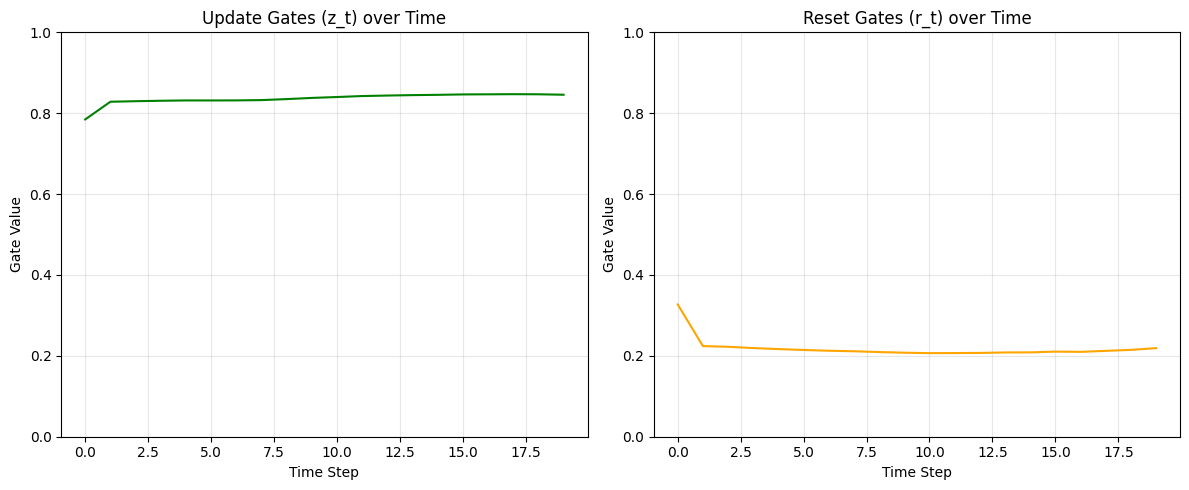

In [28]:

# Plot gates
fig = plot_gru_gates(update_gates, reset_gates, save_name="gru_gates_analysis")